# Predicting fire intensity

Does weather help predict FRP beyond location and season? Does a small neural network do better than a linear model?

Plan:
1. Load the [hotspot data](https://huggingface.co/datasets/mateus-pcosta/brazil-wildfire-geospatial-dataset) and remove rows without a valid FRP target.
2. Train on 100,000 sampled rows from 2018-2022. Use 2023 for validation, 2024 for testing, and 2025 as another check.
3. Compare a median baseline, Ridge with location/season, and Ridge with weather added.
4. Train a small MLP with the weather features. Use validation log MAE to choose its stopping epoch and the final model.
5. Compare the later-year errors and plot actual vs. predicted FRP.

We're estimating FRP (in MW) for fires that were already detected, not how much land burned or whether a new fire will start. The weather is from the same day as each detection, so this is more of a look back than a forecast.

In [1]:
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub import hf_hub_download
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

params = {
    "seed": 42,
    "train_rows": 100_000,  # Use None for all training rows.
    "epochs": 40,
    "patience": 5,
    "batch_size": 256,
    "learning_rate": 0.001,
}

root = Path.cwd()
if root.name == "research":
    root = root.parent
data_dir = root / "data" / "raw"

## 1. Data

Use the same dataset version as the EDA. Sample only the training set, keep all validation and test rows.

In [2]:
columns = [
    "data_pas", "bioma", "frp", "latitude", "longitude", "altitude_m",
    "temp_c", "rh", "wind_speed", "tp_mm",
]
frames = []
for year in range(2018, 2026):
    path = hf_hub_download(
        repo_id="mateus-pcosta/brazil-wildfire-geospatial-dataset",
        repo_type="dataset",
        revision="23181de1a54d81e8044aa7d69fc5597ae96e7a5c",
        filename=f"focos_analise/focos_enriquecido_{year}.parquet",
        local_dir=data_dir,
    )
    frames.append(pd.read_parquet(path, columns=columns))

data = pd.concat(frames, ignore_index=True)
del frames
valid = np.isfinite(data["frp"]) & (data["frp"] >= 0)
print(f"Removed {(~valid).sum():,} rows with invalid FRP")
data = data.loc[valid].copy()
data["data_pas"] = pd.to_datetime(data["data_pas"])
year = data["data_pas"].dt.year

train = data.loc[year <= 2022].copy()
if params["train_rows"] is not None:
    train = train.sample(
        n=min(params["train_rows"], len(train)), random_state=params["seed"]
    ).sort_index()
validation = data.loc[year == 2023].copy()
test = data.loc[year == 2024].copy()
check = data.loc[year == 2025].copy()
print(f"Train: {len(train):,}, validation: {len(validation):,}")
print(f"Test: {len(test):,}, 2025 check: {len(check):,}")

Removed 2,540 rows with invalid FRP
Train: 100,000, validation: 175,266
Test: 266,001, 2025 check: 130,051


## 2. Features

Start with coordinates, altitude, biome, and month. Then add temperature, humidity, wind, and rainfall. Leave out IDs, risk scores, and static 2021 land cover.

Fit imputation and scaling on training rows only. Predict `log1p(frp)` to reduce the effect of the long right tail.

Also report errors in MW.

In [10]:
location_features = ["latitude", "longitude", "altitude_m", "month_sin", "month_cos"]
weather_features = location_features + ["temp_c", "rh", "wind_speed", "tp_mm"]
for rows in [train, validation, test, check]:
    # Sine/cosine keeps December and January close together.
    month = rows["data_pas"].dt.month
    rows["month_sin"] = np.sin(2 * np.pi * month / 12)
    rows["month_cos"] = np.cos(2 * np.pi * month / 12)
    rows[weather_features] = rows[weather_features].replace([np.inf, -np.inf], np.nan)
    rows["bioma"] = rows["bioma"].fillna("Missing")

y_train = np.log1p(train["frp"].to_numpy())
y_validation = np.log1p(validation["frp"].to_numpy())


def make_preprocessor(features):
    numeric = Pipeline([
        ("fill", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("numeric", numeric, features),
        ("biome", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["bioma"]),
    ])


def predict(model, rows):
    # Convert back to MW and prevent negative predictions.
    return np.expm1(np.maximum(model.predict(rows), 0))


def scores(actual, predicted):
    return {
        "log_MAE": mean_absolute_error(np.log1p(actual), np.log1p(predicted)),
        "MAE_MW": mean_absolute_error(actual, predicted),
        "RMSE_MW": root_mean_squared_error(actual, predicted),
        "R2": r2_score(actual, predicted),
    }

## 3. Baselines

Before trying the neural network, let's use something simple to compare it with. First predict the training set's median FRP for every row. This ignores all the features and gives us a starting point. The median is useful here because a few very large FRP values can pull the mean upward.

Next try Ridge regression, which is linear regression with a penalty on large coefficients. One model gets location, altitude, biome, and month. The other gets those same features plus weather.

Compare their errors on the 2023 validation set. If adding weather lowers the error, that suggests it helps beyond knowing where and when the fires were detected. We'll also have a baseline to check whether the neural network is worth using.

In [4]:
training_median = train["frp"].median()
validation_predictions = {"Median": np.full(len(validation), training_median)}
models = {}
for name, features in [
    ("Ridge: location", location_features), ("Ridge: weather", weather_features)
]:
    model = Pipeline([
        ("prepare", make_preprocessor(features)),
        ("model", Ridge(alpha=1.0)),
    ])
    with threadpool_limits(limits=1):
        model.fit(train, y_train)
        validation_predictions[name] = predict(model, validation)
    models[name] = model

validation_scores = pd.DataFrame({
    name: scores(validation["frp"], prediction)
    for name, prediction in validation_predictions.items()
}).T
display(validation_scores.round(4))

,log_MAE,MAE_MW,RMSE_MW,R2
Median,0.7377,39.5369,120.5650,-0.0439
Ridge: location,0.7351,39.5450,119.2227,-0.0208
Ridge: weather,0.7220,39.2253,118.6746,-0.0114


## 4. Neural network

Try two hidden layers (32 and 16 units) with the same weather features. After each epoch, check 2023 log MAE. Keep the best weights and stop after five epochs without improvement.

In [5]:
# Reuse the preprocessing already fitted on the training set.
preprocessor = models["Ridge: weather"].named_steps["prepare"]
train_features = preprocessor.transform(train)
validation_features = preprocessor.transform(validation)
model = MLPRegressor(
    hidden_layer_sizes=(32, 16), alpha=0.001,
    batch_size=params["batch_size"], learning_rate_init=params["learning_rate"],
    early_stopping=False, random_state=params["seed"],
)

best_error = np.inf
waiting = 0
validation_errors = []
with threadpool_limits(limits=1):
    for epoch in range(1, params["epochs"] + 1):
        model.partial_fit(train_features, y_train)
        prediction = np.maximum(model.predict(validation_features), 0)
        error = mean_absolute_error(y_validation, prediction)
        validation_errors.append(error)

        # Copy the best weights before the next update changes them.
        if error < best_error:
            best_error = error
            best_model = deepcopy(model)
            best_epoch = epoch
            waiting = 0
        else:
            waiting += 1
        if waiting >= params["patience"]:
            break

models["MLP: weather"] = Pipeline([
    ("prepare", preprocessor), ("model", best_model)
])
with threadpool_limits(limits=1):
    validation_predictions["MLP: weather"] = predict(models["MLP: weather"], validation)
print(f"Best epoch: {best_epoch}, validation log MAE: {best_error:.4f}")

Best epoch: 9, validation log MAE: 0.7114


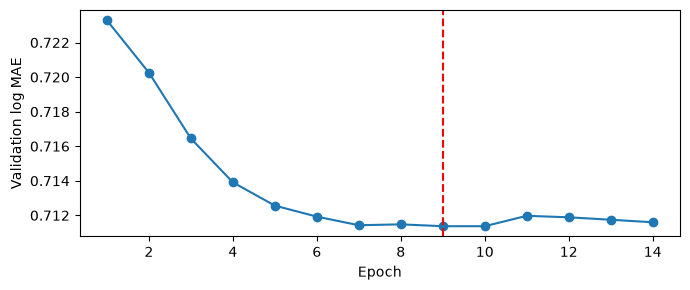

,log_MAE,MAE_MW,RMSE_MW,R2
Median,0.7377,39.5369,120.5650,-0.0439
Ridge: location,0.7351,39.5450,119.2227,-0.0208
Ridge: weather,0.7220,39.2253,118.6746,-0.0114
MLP: weather,0.7114,38.9498,118.2141,-0.0036


Selected model: MLP: weather


In [6]:
plt.figure(figsize=(7, 3))
plt.plot(range(1, len(validation_errors) + 1), validation_errors, marker="o")
plt.axvline(best_epoch, color="red", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("Validation log MAE")
plt.tight_layout()
plt.show()

validation_scores = pd.DataFrame({
    name: scores(validation["frp"], prediction)
    for name, prediction in validation_predictions.items()
}).T
selected_model = validation_scores["log_MAE"].idxmin()
display(validation_scores.round(4))
print(f"Selected model: {selected_model}")

## 5. Test results

Evaluate the same models on 2024 and 2025 without refitting or changing the selected model. Lower MAE/RMSE is better; higher R-squared is better.

In [7]:
results = []
test_predictions = {}
with threadpool_limits(limits=1):
    for year, rows in [(2024, test), (2025, check)]:
        predictions = {"Median": np.full(len(rows), training_median)}
        for name, model in models.items():
            predictions[name] = predict(model, rows)
        for name, prediction in predictions.items():
            results.append({
                "year": year, "model": name, **scores(rows["frp"], prediction)
            })
        test_predictions[year] = predictions[selected_model]

results = pd.DataFrame(results).set_index(["year", "model"])
display(results.round(4))

log_MAE   MAE_MW   RMSE_MW      R2
year model                                              
2024 Median            0.8112  53.8504  161.6826 -0.0670
     Ridge: location   0.7948  53.3213  159.7849 -0.0421
     Ridge: weather    0.7832  53.0521  158.2497 -0.0222
     MLP: weather      0.7773  52.9571  157.4695 -0.0121
2025 Median            0.7778  37.6004  107.9721 -0.0366
     Ridge: location   0.7783  37.8177  106.7971 -0.0142
     Ridge: weather    0.7568  37.3555  106.0614 -0.0003
     MLP: weather      0.7537  37.3656  105.6218  0.0080

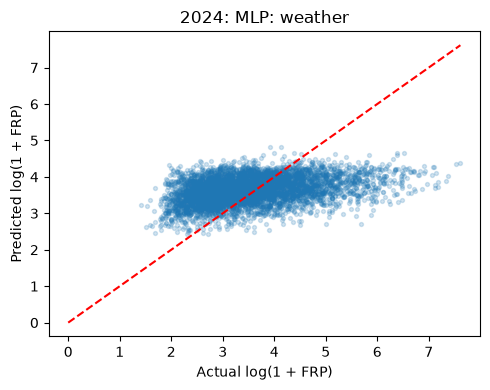

In [8]:
# Plot a sample so the figure stays readable.
plot_rows = test[["frp"]].copy()
plot_rows["predicted"] = test_predictions[2024]
plot_rows = plot_rows.sample(n=min(5000, len(plot_rows)), random_state=params["seed"])

figure, axis = plt.subplots(figsize=(5, 4))
axis.scatter(np.log1p(plot_rows["frp"]), np.log1p(plot_rows["predicted"]), s=8, alpha=0.2)
limit = np.log1p(plot_rows[["frp", "predicted"]].to_numpy().max())
axis.plot([0, limit], [0, limit], "r--")
axis.set(
    title=f"2024: {selected_model}",
    xlabel="Actual log(1 + FRP)", ylabel="Predicted log(1 + FRP)",
)
figure.tight_layout()
plt.show()

## Takeaways

* Weather helped Ridge: validation log MAE went from 0.7351 to 0.7220.
* The MLP did a little better at 0.7114, using the weights from epoch 9. It also had the lowest log MAE in 2024 and 2025.
* The improvement is small. Its 2024 MW MAE is about 53, and R-squared is still slightly negative. The scatter plot shows it misses the highest FRP values.

This is one run with one training sample. Nearby detections can be related, and we already looked at these years in EDA. Next we should consider repeating with a few seeds and try holding out locations, not only years.